# Uji Stasioneritas — Harga Mingguan Bawang Merah di Kota Surabaya

Data harga harian diagregasi menjadi **data mingguan** (rata-rata per minggu, 193 pengamatan) agar pola musiman **tahunan** (m = 52) dapat dimodelkan dan derau harian berkurang. Notebook ini menguji stasioneritas seri mingguan tersebut menggunakan uji ADF dan KPSS sebagai tahap awal sebelum pemodelan SARIMA.

In [1]:
import sys

print(sys.executable)

c:\Users\USER\anaconda3\envs\rpk-env\python.exe


In [2]:
import sys

!{sys.executable} -m pip install statsmodels

In [3]:
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf

warnings.filterwarnings("ignore")

In [ ]:
KOMODITAS = "Bawang Merah (Kualitas Lokal)"

df = pd.read_csv(
    "C:/Users/USER/Documents/SEMESTER 5/SARIMA_XGBoost Bawang Merah/harga_komoditas.csv",
    encoding="utf-8-sig",
    parse_dates=["tanggal"]
)
df.head()

,tanggal,komoditas,satuan,harga
0,2023-01-01,Air Mineral (Aqua Galon),19 Ltr/Galon,18000.00000
1,2023-01-01,Bawang Bombay,Kg,21714.28571
2,2023-01-01,Bawang Merah (Kualitas Lokal),Kg,31857.14286
3,2023-01-01,Bawang Putih (Jenis Kating),Kg,26714.28571
4,2023-01-01,Bawang Putih (Jenis Sinco),Kg,23000.00000


In [5]:
def ambil_series(nama):
    s = (
        df[df["komoditas"] == nama]
        .set_index("tanggal")["harga"]
        .sort_index()
    )

    # data harian -> diratakan menjadi mingguan (musiman tahunan, m = 52)
    return s.asfreq("D").interpolate().resample("W").mean()

Mengambil data harga berdasarkan nama komoditas, lalu menyusunnya secara kronologis. Data harian terlebih dahulu dirapikan menjadi frekuensi harian penuh dan celah tanggal diisi dengan interpolasi, kemudian **diagregasi menjadi rata-rata mingguan**. Agregasi ini dilakukan karena pola musiman harga bawang merah bersifat tahunan; pada data mingguan, satu siklus tahunan setara dengan 52 periode (m = 52) sehingga dapat dimodelkan oleh SARIMA, sekaligus mengurangi derau harian yang tidak relevan.

In [6]:
def uji_stasioner(s):
    s = s.dropna()

    adf_p = adfuller(s, autolag="AIC")[1]
    kpss_p = kpss(s, regression="c", nlags="auto")[1]

    return adf_p, kpss_p

Untuk mengetahui apakah data harga mingguan telah memenuhi asumsi stasioneritas atau belum. Pengujian dilakukan menggunakan dua metode, yaitu Augmented Dickey-Fuller (ADF) dan Kwiatkowski-Phillips-Schmidt-Shin (KPSS). Metode ADF memiliki hipotesis nol bahwa data tidak stasioner, sedangkan KPSS memiliki hipotesis nol bahwa data bersifat stasioner. Penggunaan kedua metode tersebut bertujuan memperoleh hasil pengujian yang lebih menyeluruh. Hasil ditentukan berdasarkan nilai p-value dengan tingkat signifikansi 5%.

In [7]:
def label(adf_p, kpss_p):
    # ADF: H0 = tidak stasioner
    # KPSS: H0 = stasioner

    return (
        "Stasioner"
        if (adf_p < 0.05 and kpss_p > 0.05)
        else "Tidak stasioner"
    )

Menentukan kesimpulan dari hasil pengujian ADF dan KPSS. Data dinyatakan stasioner apabila nilai p-value ADF kurang dari 0,05 dan nilai p-value KPSS lebih dari 0,05. Sebaliknya, apabila salah satu kriteria tidak terpenuhi, data dikategorikan belum stasioner.

Tahapan ini membantu menentukan apakah data harga masih memerlukan transformasi, seperti differencing, sebelum digunakan dalam pemodelan SARIMA.

In [8]:
def plot_nonstasioner(nama):

    s = ambil_series(nama)
    ds = s.diff().dropna()

    # Uji stasioneritas
    adf0, kpss0 = uji_stasioner(s)
    adf1, kpss1 = uji_stasioner(ds)

    fig, ax = plt.subplots(2, 3, figsize=(18, 9))

    fig.suptitle(
        f"Uji Kestasioneran (Mingguan): {nama}",
        fontsize=15,
        fontweight="bold"
    )

    # 1. Harga dan rata-rata bergerak
    ax[0, 0].plot(
        s, color="tab:blue", lw=1, label="Harga mingguan"
    )

    ax[0, 0].plot(
        s.rolling(13).mean(),
        color="tab:red",
        lw=2,
        label="Rata-rata 13 minggu"
    )

    ax[0, 0].set_title("Harga & rata-rata bergerak")
    ax[0, 0].legend()

    # 2. Simpangan baku bergerak
    ax[0, 1].plot(
        s.rolling(13).std(),
        color="tab:orange",
        lw=2
    )

    ax[0, 1].set_title("Simpangan baku bergerak 13 minggu")

    # 3. ACF data asli
    plot_acf(s, lags=52, ax=ax[0, 2])
    ax[0, 2].set_title("ACF data asli")

    # 4. Differencing orde 1
    ax[1, 0].plot(ds, color="tab:green", lw=0.8)
    ax[1, 0].axhline(0, color="black", lw=0.8)
    ax[1, 0].set_title("Setelah differencing orde 1")

    # 5. ACF setelah differencing
    plot_acf(ds, lags=52, ax=ax[1, 1])
    ax[1, 1].set_title("ACF setelah differencing")

    # 6. Ringkasan uji formal
    ax[1, 2].axis("off")

    teks = (
        "HASIL UJI FORMAL\n\n"
        "Data asli:\n"
        f"  ADF p-value  = {adf0:.4f}\n"
        f"  KPSS p-value = {kpss0:.4f}\n"
        f"  Kesimpulan   : {label(adf0, kpss0)}\n\n"
        "Setelah differencing (d=1):\n"
        f"  ADF p-value  = {adf1:.4f}\n"
        f"  KPSS p-value = {kpss1:.4f}\n"
        f"  Kesimpulan   : {label(adf1, kpss1)}\n\n"
        "ADF: H0 = tidak stasioner\n"
        "KPSS: H0 = stasioner"
    )

    ax[1, 2].text(0, 0.95, teks, va="top", family="monospace", fontsize=11)

    plt.tight_layout()

    plt.savefig(
        f"stasioneritas_{nama.split()[0].lower()}_mingguan.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

    return {
        "Komoditas": nama,
        "ADF p (asli)": round(adf0, 4),
        "KPSS p (asli)": round(kpss0, 4),
        "Kesimpulan (asli)": label(adf0, kpss0),
        "ADF p (diff)": round(adf1, 4),
        "KPSS p (diff)": round(kpss1, 4),
        "Kesimpulan (diff)": label(adf1, kpss1)
    }

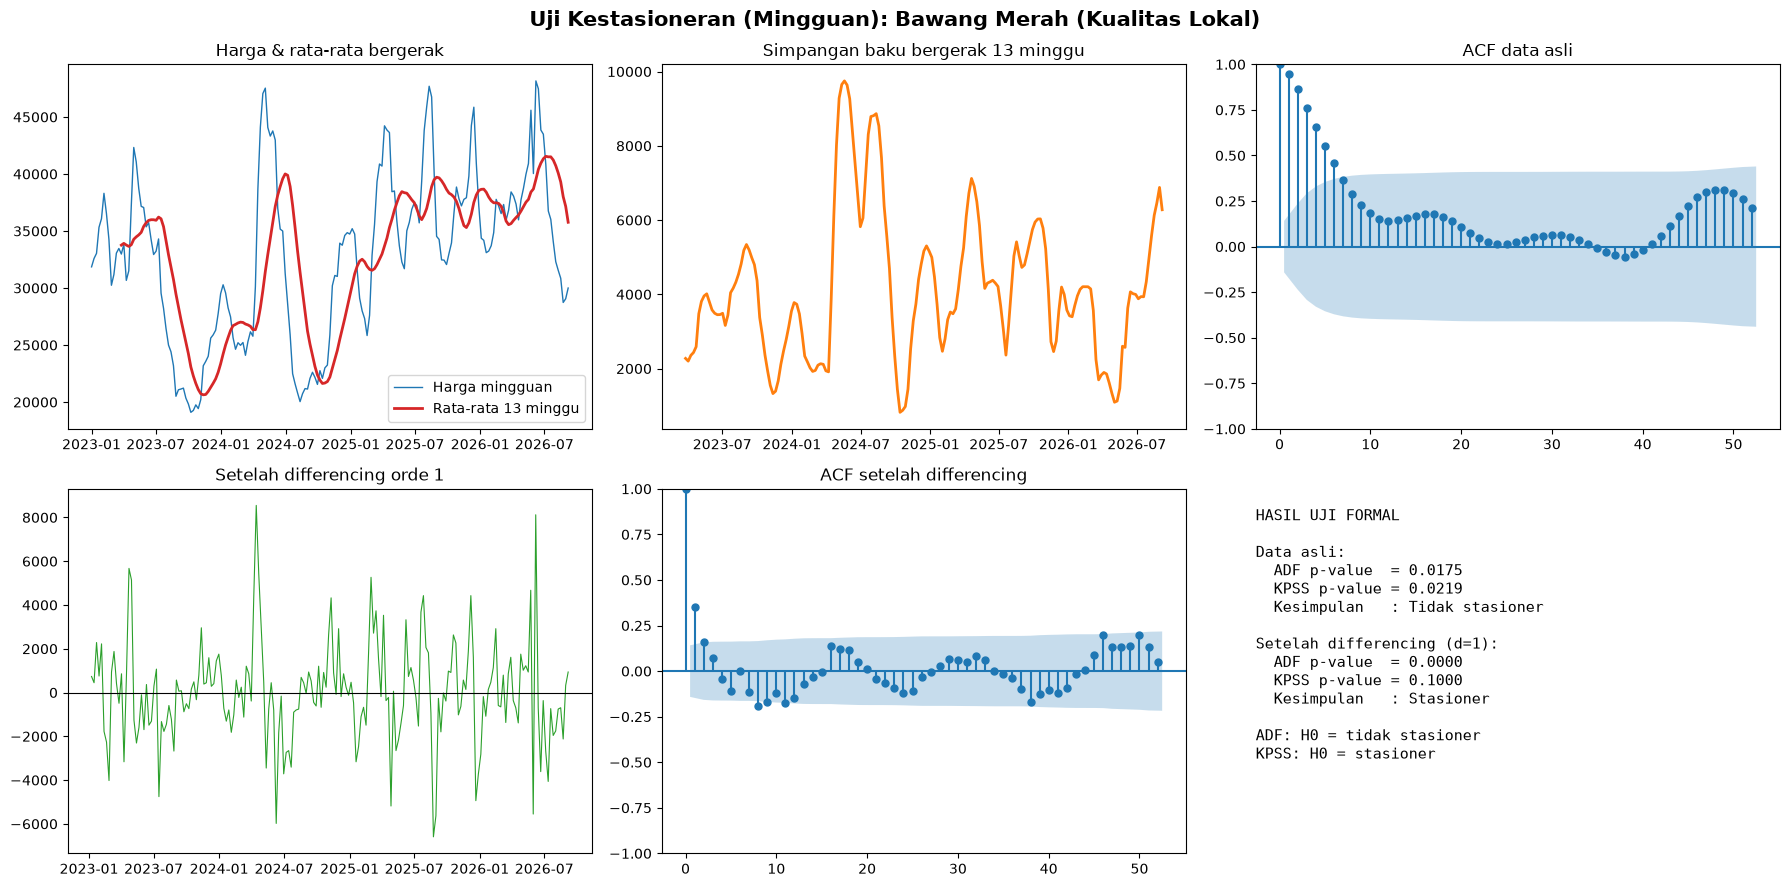

In [9]:
ringkasan = pd.DataFrame([plot_nonstasioner(KOMODITAS)])

Berdasarkan hasil uji ADF dan KPSS pada data mingguan (lihat sel ringkasan di atas), harga Bawang Merah (Kualitas Lokal) belum memenuhi asumsi stasioneritas pada data asli, sehingga masih memerlukan transformasi. Setelah dilakukan differencing orde 1, data menjadi stasioner.

Nilai p-value selengkapnya ditampilkan pada output dan menjadi dasar penetapan **d = 1** pada pemodelan SARIMA. (Angka ini juga yang dicantumkan pada bagian Data & Karakteristik di poster, sehingga hasilnya konsisten dan dapat diperiksa ulang.)

Berdasarkan hasil pengujian stasioneritas terhadap harga mingguan Bawang Merah (Kualitas Lokal) di Kota Surabaya, data belum stasioner pada kondisi asli, tetapi menjadi stasioner setelah differencing orde 1.

Hasil ini menunjukkan bahwa data memerlukan perlakuan differencing (d = 1) agar memenuhi asumsi stasioneritas. Pengujian stasioneritas menjadi tahapan penting sebelum pemodelan SARIMA, karena hasilnya digunakan untuk menentukan orde differencing pada model.

In [10]:
print("RINGKASAN HASIL UJI STASIONERITAS (DATA MINGGUAN)")

display(ringkasan)

RINGKASAN HASIL UJI STASIONERITAS (DATA MINGGUAN)


,Komoditas,ADF p (asli),KPSS p (asli),Kesimpulan (asli),ADF p (diff),KPSS p (diff),Kesimpulan (diff)
0,Bawang Merah (Kualitas Lokal),0.0175,0.0219,Tidak stasioner,0.0,0.1,Stasioner
